In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm

import json

plt.style.use("mystyle")

In [8]:
# # Disclaimer: VERY LONG
# get_device_name = lvr.experiments_helpers.get_device_name

# def extract_lvr(device: str, experiment_uuid: str):
# 	df = pd.read_csv(f"data/devices/{device}.csv")
# 	df = df[(df["exp_uuid"] == experiment_uuid) & (df["pattern"] == "WEAK_RESET")]
# 	return 1./df["resistance"].to_numpy()

# with open("data/experiments/lowvolt_aa_endurance/params.json", "r") as f:
# 	endurance_params = json.load(f)
# sel_devs = endurance_params["selected_devices"]
# experiments = endurance_params["sister_experiments"]

# gss_per_dev = [
#     np.concatenate([
#         extract_lvr(get_device_name(d[0], d[1], d[2]), exp)
#         for exp in experiments
#     ])
#     for d in sel_devs
# ]
#
# np.save("plots_out/_buffer_endurance_pulses.npy", np.stack(gss_per_dev).reshape(4, -1, 5000))
gss_per_dev = np.load("plots_out/_buffer_endurance_pulses.npy").reshape(4, -1)
gss_per_dev = [gss.reshape((-1, 5000)) for gss in gss_per_dev]

In [9]:
gss_per_dev[0].size, gss_per_dev[0].shape

(1485000, (297, 5000))

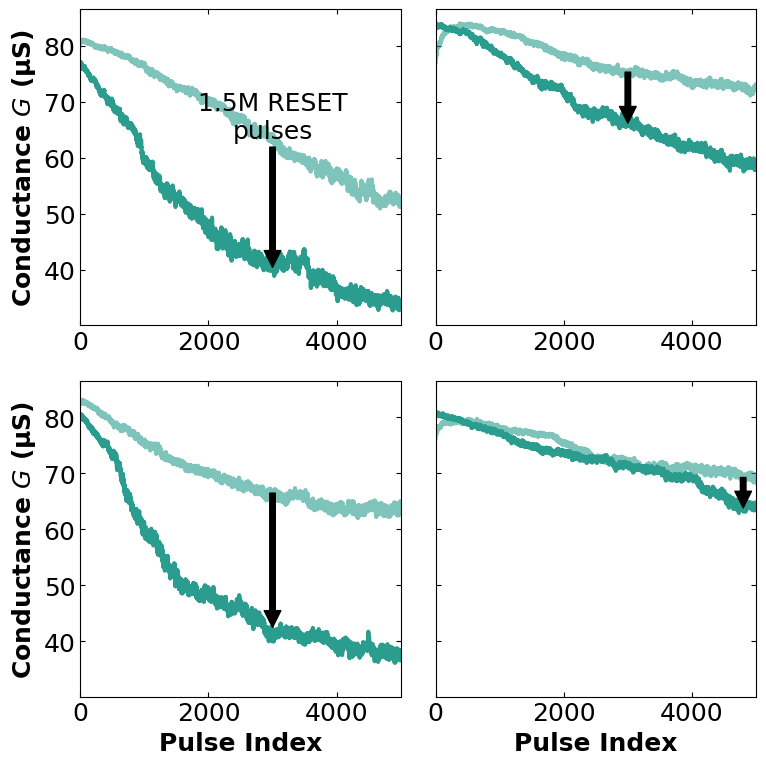

In [10]:
xs = np.arange(5000)
avg_count = 20

fig, axs = plt.subplots(2, 2, figsize=(8,8), sharey=True)
axs = axs.ravel()

for ax, gss in zip(axs, gss_per_dev):
	gss_begin = np.mean(gss[:avg_count, :], axis=0)
	gss_last  = np.mean(gss[-avg_count:, :], axis=0)
	ax.plot(xs, gss_begin * 1e6, c="C2", alpha=.6)
	ax.plot(xs, gss_last * 1e6, c="C2")
	ax.set_xlim(0, 5000)

	arrow_x = 4800 if ax == axs[-1] else 3000
	ax.annotate(
		"1.5M RESET\npulses" if ax == axs[0] else "",
		xy=(arrow_x, gss_last[arrow_x]*1e6), xytext=(arrow_x, gss_begin[arrow_x]*1e6),
		arrowprops=dict(facecolor='black', shrink=0.01),
		ha="center"
	)

axs[0].set_ylabel("Conductance $G$ (µS)", fontdict={"weight": "bold"})
axs[2].set_ylabel("Conductance $G$ (µS)", fontdict={"weight": "bold"})
axs[2].set_xlabel("Pulse Index", fontdict={"weight": "bold"})
axs[3].set_xlabel("Pulse Index", fontdict={"weight": "bold"})
plt.tight_layout()
plt.savefig("plots_out/d_endurance.svg", dpi=300, bbox_inches="tight")